# INFO 2950 Project — Phase II

**Group:** Kai Harashima (kh862), Skye Moore (sbm232)

**Project:** Analyzing chess games from the Lichess and Chess.com APIs

**Due:** Oct. 15 (peer review), Oct. 20 (final grading)

---

## Setup

*Imports and configuration used throughout the notebook.*

In [ ]:
# Imports
import numpy as np
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt

---
# Part 1: Data Collection and Exploratory Data Analysis

## 1. Research Question(s)

How does the probability of blundering depend on how much time a player has? How
does that relationship change between bullet, blitz, rapid, and classical time modes?

## 2. Data Collection and Cleaning

*Initial draft of the data cleaning appendix. Document every step that takes the raw data file(s) and turns them into the analysis-ready dataset. Include text cells describing data collection (downloading, scraping, APIs, etc.) and text cells describing any additional curation/cleaning (merging data frames, filtering, transformations of variables, etc.). Include code cells for curation/cleaning, but not collection.*

*Note: Save data in intermediate files at several points so you are not starting from scratch every time something changes.*

### 2.1 Data Collection

*Describe how the raw data was obtained (sources, APIs, parameters, dates collected). Text only — no collection code here.*

- **Source(s):**
    - Bullet: https://lichess.org/tournament/qOuXu5XQ
    - Blitz: https://lichess.org/tournament/RFD0ylGd
    - Rapid: https://lichess.org/tournament/mvHPAYHc
    - Classical: https://lichess.org/tournament/jqxM88Wl

- **Collection method:** python script
- **Date(s) collected:** 10/18
- **Raw file location(s):** ../raw-data

### 2.2 Loading Raw Data

*Read in the raw data file(s).*

In [ ]:
# Load raw data

total = []

games_bullet = pd.read_json("../data/raw/qOuXu5XQ.ndjson", lines=True)
games_blitz = pd.read_json("../data/raw/RFD0ylGd.ndjson", lines=True)
games_rapid = pd.read_json("../data/raw/mvHPAYHc.ndjson", lines=True)
games_classical = pd.read_json("../data/raw/jqxM88Wl.ndjson", lines=True)

total.append(games_bullet)
total.append(games_blitz)
total.append(games_rapid)
total.append(games_classical)
full_df = pd.concat(total, ignore_index=True)

print(full_df.shape)
full_df.head()

(29428, 17)


,id,rated,variant,speed,perf,createdAt,lastMoveAt,status,source,players,winner,opening,moves,clocks,analysis,arenaTour,clock
0,Xl7ZoEek,True,standard,bullet,bullet,1791831524597,1791831590607,mate,arena,"{'white': {'user': {'name': 'Jg2405', 'id': 'j...",white,"{'eco': 'C20', 'name': 'King's Pawn Game: Beye...",e4 e5 d4 d5 dxe5 d4 Nf3 Bg4 Qxd4 Qxd4 Nxd4 c5 ...,"[3003, 3003, 2955, 2979, 2835, 2875, 2707, 282...","[{'eval': 18}, {'eval': 22}, {'eval': -11}, {'...","{'id': 'qOuXu5XQ', 'name': 'Weekly Bullet Arena'}","{'initial': 60, 'increment': 0, 'totalTime': 60}"
1,oKqBjl1V,True,standard,bullet,bullet,1791831524597,1791831554618,mate,arena,"{'white': {'user': {'name': 'Plini2020', 'id':...",black,"{'eco': 'C20', 'name': 'Center Game', 'ply': 3}",e4 e5 d4 f5 dxe5 fxe4 Nc3 g6 Be3 Bg7 Qd2 Ne7 O...,"[6003, 6003, 5947, 5947, 5891, 5859, 5843, 580...",NaN,"{'id': 'qOuXu5XQ', 'name': 'Weekly Bullet Arena'}","{'initial': 60, 'increment': 0, 'totalTime': 60}"
2,XpFCVDQo,True,standard,bullet,bullet,1791831507010,1791831583075,resign,arena,"{'white': {'user': {'name': 'IcelordBg', 'flai...",black,"{'eco': 'A43', 'name': 'Benoni Defense: Old Be...",d4 c5 c4 cxd4 Qxd4 Nc6 Qd1 Nf6 Nc3 e6 a3 d5 cx...,"[6003, 6003, 6003, 5987, 5939, 5987, 5923, 588...","[{'eval': 15}, {'eval': 61}, {'eval': 0, 'best...","{'id': 'qOuXu5XQ', 'name': 'Weekly Bullet Arena'}","{'initial': 60, 'increment': 0, 'totalTime': 60}"
3,g4SUkgBB,True,standard,bullet,bullet,1791831507010,1791831545776,mate,arena,"{'white': {'user': {'name': 'LikaLia157', 'id'...",black,"{'eco': 'D00', 'name': 'Queen's Pawn Game', 'p...",d4 d5 c3 Nc6 Nf3 Bg4 e3 Nf6 Be2 e6 Nbd2 Bd6 h3...,"[6003, 6003, 6003, 5923, 6003, 5779, 6003, 564...",NaN,"{'id': 'qOuXu5XQ', 'name': 'Weekly Bullet Arena'}","{'initial': 60, 'increment': 0, 'totalTime': 60}"
4,PNjEGGkv,True,standard,bullet,bullet,1791831507010,1791831537227,mate,arena,"{'white': {'user': {'name': 'gmcg44', 'id': 'g...",white,"{'eco': 'C50', 'name': 'Four Knights Game: Ita...",e4 e5 Nc3 Nc6 Nf3 Nf6 Bc4 Bc5 d3 O-O O-O d6 Nd...,"[6003, 6003, 6003, 5971, 5979, 5923, 5931, 588...",NaN,"{'id': 'qOuXu5XQ', 'name': 'Weekly Bullet Arena'}","{'initial': 60, 'increment': 0, 'totalTime': 60}"


### 2.3 Cleaning Steps

*Describe each cleaning/curation step and why it was needed.*

**Step 1:** First, we converted the player and clock data from nested dictionaries, giving each relevant key/value an individual column so that player Elo ratings, starting time, and increment could be analyzed. We also added two columns representing whether one of the players was berserk or provisional so that we can filter those games out later.

In [ ]:
# Cleaning step 1
def get_white_rating(p):
    return p["white"]["rating"]


def get_black_rating(p):
    return p["black"]["rating"]


def either_berserk(p):
    return p["white"].get("berserk", False) or p["black"].get("berserk", False)


def either_provisional(p):
    return p["white"].get("provisional", False) or p["black"].get("provisional", False)


def get_clock_initial(c):
    return c["initial"]


def get_clock_increment(c):
    return c["increment"]


games_df = full_df.copy()
games_df["white_rating"] = games_df["players"].apply(get_white_rating)
games_df["black_rating"] = games_df["players"].apply(get_black_rating)
games_df["berserk"] = games_df["players"].apply(either_berserk)
games_df["provisional"] = games_df["players"].apply(either_provisional)
games_df["clock_initial"] = games_df["clock"].apply(get_clock_initial)
games_df["clock_increment"] = games_df["clock"].apply(get_clock_increment)

**Step 2:** We dropped every game without a Stockfish evaluation, as we were unable to identify blunders for those games. We dropped berserk games because they changed one player's starting time, affecting our time measurements. We also dropped games with provisional player elos because they were more likely to skew our data. We removed the columns `rated`, `variant`, and `source` because they had the same value for every game. We also dropped the `perf` column because it duplicated speed, `arenaTour` which repeats the tournament information, and finally `createdAt`, `lastMoveAt`, and `opening` because they are not needed for our analysis.

In [ ]:
# Cleaning step 2

# drop games without analysis
games_df = games_df.loc[games_df["analysis"].notna()]

# drop berserk/provisional
games_df = games_df.loc[~games_df["berserk"] & ~games_df["provisional"]]

# drop unneeded columns:
games_df = games_df.drop(
    columns=[
        "rated",
        "variant",
        "source",
        "perf",
        "arenaTour",
        "createdAt",
        "lastMoveAt",
        "opening",
        "players",
        "clock",
        "berserk",
        "provisional",
    ]
)
games_df = games_df.rename(columns={"id": "game_id"})
games_df = games_df.reset_index(drop=True)
print(games_df.shape)
games_df.head()

(2894, 11)


,game_id,speed,status,winner,moves,clocks,analysis,white_rating,black_rating,clock_initial,clock_increment
0,XpFCVDQo,bullet,resign,black,d4 c5 c4 cxd4 Qxd4 Nc6 Qd1 Nf6 Nc3 e6 a3 d5 cx...,"[6003, 6003, 6003, 5987, 5939, 5987, 5923, 588...","[{'eval': 15}, {'eval': 61}, {'eval': 0, 'best...",2716,2444,60,0
1,euCaFbR9,bullet,outoftime,white,f4 d5 Nf3 c5 g3 Nc6 Bg2 Bg4 O-O e6 h3 Bxf3 exf...,"[6003, 6003, 6003, 5771, 6003, 5603, 6003, 514...","[{'eval': -23}, {'eval': -17}, {'eval': -24}, ...",1773,1188,60,0
2,eptF8Xmh,bullet,resign,white,d4 d6 Nf3 Nf6 g3 h5 Bg2 g6 h4 Nbd7 b3 Bg7 Bb2 ...,"[6003, 6003, 5891, 5963, 5835, 5963, 5787, 594...","[{'eval': 15}, {'eval': 60}, {'eval': 48}, {'e...",2198,2135,60,0
3,RrP8uNYV,bullet,mate,white,d4 g5 c4 g4 Nc3 Bg7 e4 c5 d5 Bxc3+ bxc3 Qa5 f3...,"[6003, 6003, 6003, 5963, 5987, 5907, 5979, 581...","[{'eval': 15}, {'eval': 179, 'best': 'g8f6', '...",1769,1586,60,0
4,IeMfp0On,bullet,mate,white,d4 Nf6 c4 e6 Nc3 d5 cxd5 exd5 Bg5 Bg4 Bxf6 Qxf...,"[6003, 6003, 6003, 5979, 5923, 5979, 5835, 597...","[{'eval': 15}, {'eval': 15}, {'eval': 16}, {'e...",1330,1801,60,0


**Step 3:** The moves and analysis were represented as nested lists in the game data. So we expanded each game into a table that had one row per ply (individual player move). We kept the data needed for our analysis: the game speed, player Elo rating, percentage time remaining, and Stockfish eval. Because the clocks list records time after each move, we had to calculate time before a move using that player's previous clock value. We divided time remaining by the starting clock time and multiplied by 100 to standardize time pressure to a percentage across the four game speeds. For every move, we used the corresponding Stockfish analysis entry to identify whether it was a blunder or not. We stored this data in `is_blunder`, where “1” represents a blunder and “0” is a non-blunder.

In [ ]:
# Cleaning step 3
def get_judgment(entry):
    if "judgment" in entry:
        return entry["judgment"]["name"]
    return "None"


def game_to_df(game):
    moves = game["moves"].split()
    n = len(moves)
    start = game["clock_initial"] * 100
    clock_before = [start, start] + list(game["clocks"][: n - 2])
    df = pd.DataFrame({"ply": range(1, n + 1), "clock_before": clock_before})
    df["game_id"] = game["game_id"]
    df["speed"] = game["speed"]
    df["color"] = (df["ply"] % 2 == 1).map({True: "white", False: "black"})
    df["rating"] = df["color"].map(
        {"white": game["white_rating"], "black": game["black_rating"]}
    )
    df["pct_time_remaining"] = 100 * df["clock_before"] / start

    df["judgment"] = pd.Series(game["analysis"][:n]).apply(get_judgment)
    df["judgment"] = df["judgment"].replace(np.nan, "None")
    return df


move_frames = games_df.apply(game_to_df, axis=1)
moves_df = pd.concat(list(move_frames), ignore_index=True)
moves_df = moves_df.loc[
    :, ["game_id", "speed", "ply", "color", "rating", "pct_time_remaining", "judgment"]
]
moves_df["is_blunder"] = (moves_df["judgment"] == "Blunder").astype(int)

def get_phase(ply):
    if ply <= 20:
        return "opening"
    if ply <= 60:
        return "middlegame"
    return "endgame"

moves_df["phase"] = moves_df["ply"].apply(get_phase)
print(moves_df.shape)
print(moves_df["judgment"].value_counts())
moves_df.head()

(196955, 8)
judgment
None          156932
Inaccuracy     17679
Blunder        13987
Mistake         8357
Name: count, dtype: int64


,game_id,speed,ply,color,rating,pct_time_remaining,judgment,is_blunder
0,XpFCVDQo,bullet,1,white,2716,100.00,None,0
1,XpFCVDQo,bullet,2,black,2444,100.00,None,0
2,XpFCVDQo,bullet,3,white,2716,100.05,Inaccuracy,0
3,XpFCVDQo,bullet,4,black,2444,100.05,None,0
4,XpFCVDQo,bullet,5,white,2716,100.05,None,0


### 2.4 Saving the Analysis-Ready Dataset

*Write the cleaned dataset to `data/processed/`.*

In [ ]:
# Save cleaned data
games_out = games_df.drop(columns=["moves", "clocks", "analysis"])

games_out.to_csv("../data/processed/games.csv", index=False)
moves_df.to_csv("../data/processed/moves.csv", index=False)

print("games:", games_out.shape, "| moves:", moves_df.shape)

games: (2894, 8) | moves: (196955, 8)


## 3. Data Description

*Initial draft of the data description, about the **analysis-ready** data. Inspired by the format in Gebru et al., 2018 ("Datasheets for Datasets"), sections 3.1–3.5.*

**What are the observations (rows) and the attributes (columns)?**

- We have two tables. In games.csv, there is one row per game. We have 2894 rows; each contains game id, speed (time control), status, winner, both ratings, and starting clock. In moves.csv, there one row per ply (a ply is one player's individual move, two plys are one "full" move). moves.csv has 196,955 rows containing speed, ply number, color, mover's rating, percent of starting time remaining, engine judgment, and a blunder indicator (0 or 1), and game phase (opening for plies 1-20, middlegame for 21-60, endgame for 61+).

**Why was this dataset created?**

- We created this dataset to test if the probability of a blunder changes based on time remaining, and if the relationship differs across bullet, blitz, rapid, and classical time controls.

**How did you create this dataset? What tools, procedures, and data sources did you use?**

- We used Python to pull the Lichess tournament games as NDJSON files for four weekly arenas. We then turned into dataframes and cleaned using pandas (see section 2).

**What processes might have influenced what data was observed and recorded and what was not?**

- We have only included arena tournament games, which limits our selection to players who chose to enter tournaments, and also limited our scope to games where someone requested engine analysis (we couldn't tell what was a blunder otherwise). We removed games with a berserked or provisionally rated player (berserked means one player had half the normal time, which interferes with our correlation of time and blunders. Provisionally rated means that the players' elo is uncertain and so could interfere with our visualization of how the time/blunder correlation changes with elo).

**What preprocessing was done, and how did the data come to be in the form that you are using?**

- See section 2: We dropped columns that weren't needed for our analysis, flattened the player and clock nested dicts into individual columns containing the relevant info, filtered out berserk/provisional/unanalyzed games, and created a new dataset for moves, containing one row per ply and also normalizing the clock to percent time remaining to adjust for the difference in scale between different time controls.

**If people are involved, were they aware of the data collection and if so, what purpose did they expect the data to be used for?**

- Lichess users already agree to public game data under the site's terms. We dropped usernames from the data, as they weren't relevant to our study.

**Where can your raw source data be found, if applicable?** *(Provide a link to the raw data hosted on GitHub, Cornell Google Drive, or Cornell Box.)*

- https://github.com/Harashima-CS/info2950-project/tree/main/data/raw

### 3.1 Dataset Overview

*Show the structure of the analysis-ready dataset (shape, columns, dtypes, head).*

In [ ]:
# Dataset overview
print("games_out shape:", games_out.shape)
print("--------------------")
print(games_out.dtypes)
print("--------------------")
print("Games per time control:")
print(games_out["speed"].value_counts())
print("--------------------")
print("Missing values per column:")
print(games_out.isna().sum())
games_out.head()

games_out shape: (2894, 8)
--------------------
game_id              str
speed                str
status               str
winner               str
white_rating       int64
black_rating       int64
clock_initial      int64
clock_increment    int64
dtype: object
--------------------
Games per time control:
speed
bullet       1191
blitz         711
rapid         663
classical     329
Name: count, dtype: int64
--------------------
Missing values per column:
game_id             0
speed               0
status              0
winner             75
white_rating        0
black_rating        0
clock_initial       0
clock_increment     0
dtype: int64


,game_id,speed,status,winner,white_rating,black_rating,clock_initial,clock_increment
0,XpFCVDQo,bullet,resign,black,2716,2444,60,0
1,euCaFbR9,bullet,outoftime,white,1773,1188,60,0
2,eptF8Xmh,bullet,resign,white,2198,2135,60,0
3,RrP8uNYV,bullet,mate,white,1769,1586,60,0
4,IeMfp0On,bullet,mate,white,1330,1801,60,0


In [ ]:
# Second Dataset overview
print("moves_df shape:", moves_df.shape)
print("--------------------")
print(moves_df.dtypes)
print("--------------------")
print("Plies per time control:")
print(moves_df["speed"].value_counts())
print("--------------------")
print("Engine judgment counts:")
print(moves_df["judgment"].value_counts())
print("--------------------")
print("Summary of numeric columns:")
print(moves_df[["ply", "rating", "pct_time_remaining", "is_blunder"]].describe())
moves_df.head()

moves_df shape: (196955, 8)
--------------------
game_id                   str
speed                     str
ply                     int64
color                     str
rating                  int64
pct_time_remaining    float64
judgment                  str
is_blunder              int64
dtype: object
--------------------
Plies per time control:
speed
bullet       76895
blitz        50095
rapid        47477
classical    22488
Name: count, dtype: int64
--------------------
Engine judgment counts:
judgment
None          156932
Inaccuracy     17679
Blunder        13987
Mistake         8357
Name: count, dtype: int64
--------------------
Summary of numeric columns:
                 ply         rating  pct_time_remaining     is_blunder
count  196955.000000  196955.000000       196955.000000  196955.000000
mean       39.249727    1779.534097           69.709780       0.071016
std        27.874322     346.684260           29.385200       0.256853
min         1.000000     491.000000            

,game_id,speed,ply,color,rating,pct_time_remaining,judgment,is_blunder
0,XpFCVDQo,bullet,1,white,2716,100.00,None,0
1,XpFCVDQo,bullet,2,black,2444,100.00,None,0
2,XpFCVDQo,bullet,3,white,2716,100.05,Inaccuracy,0
3,XpFCVDQo,bullet,4,black,2444,100.05,None,0
4,XpFCVDQo,bullet,5,white,2716,100.05,None,0


## 4. Data Limitations

*Identify potential problems with the dataset: harms, data gaps, biases, and how these could affect the meaning of results and the impact of results on people.*

- Only 15% of games had engine analysis, when a player requested it post-gam. Analyzed games are therefore not a random sample as players who requested analysis may have been more upset or proud about the result.
- Removing berserk games dropped 24% of the data and over half of the classical games. Berserking is chosen more by confident players.
- "Blunder" is based on Lichess's threshold on centipawn loss. This is harsher in positions that are already lost and ignores whether the opponent could find and exploit the blunder.
- Moves from the same game and same player are not independent. Treat with care in the
  regression.
- Arena players skew toward active, competitive users. Results may not generalize to casual
  games.

## 5. Exploratory Data Analysis

*Perform an initial EDA. Compute relevant summary statistics and show plots applicable to the research question(s). Choose analyses deliberately (no "chart barf") and explain each one. Use the EDA to confirm/update the research question(s) and the data description.*

### 5.1 Summary Statistics

* **Blunder rate rises as the time control gets faster:** 5.2% of plies in classical are blunders, 6.4% in rapid, 7.2% in blitz, and
  finally 8.0% in bullet. Roughly 80% of plies get no engine label at all. Inaccuracies (9.0%) are more common than blunders
  (7.1%), and mistakes (4.2%) are the least common. 
  
  Because of the time increment, classical players get time back every move, so their clock rarely drains that much (on average they move with 87% of their clock left). Bullet clocks drain fast, with an average of 64% left.
  Time pressure becomes more clear in other gamemodes where 52% of bullet games and 22% of blitz games end with
  someone running out of time, versus 2% of classical games.

  Average ratings range from about 1700 to 1900, so rating differences are unlikely to explain the
  gap in blunder rate between controls.

In [ ]:
# Summary statistics
blunder_by_speed = duckdb.sql("""
    SELECT speed,
           COUNT(*) AS n_plies,
           ROUND(100 * AVG(is_blunder), 2) AS blunder_pct,
           ROUND(AVG(pct_time_remaining), 1) AS avg_pct_time
    FROM moves_df
    GROUP BY speed
    ORDER BY blunder_pct DESC
""").df()
print(blunder_by_speed)

judgment_pct = duckdb.sql("""
    SELECT judgment,
           COUNT(*) AS n_plies,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM moves_df), 2) AS pct
    FROM moves_df
    GROUP BY judgment
    ORDER BY n_plies DESC
""").df()
print(judgment_pct)
print()

games_by_speed = duckdb.sql("""
    SELECT speed,
           COUNT(*) AS n_games,
           MIN(white_rating) AS min_rating,
           ROUND(AVG(white_rating)) AS avg_rating,
           MAX(white_rating) AS max_rating,
           ROUND(100.0 * SUM(status = 'outoftime') / COUNT(*), 1) AS pct_outoftime
    FROM games_out
    GROUP BY speed
    ORDER BY n_games DESC
""").df()
print(games_by_speed)

       speed  n_plies  blunder_pct  avg_pct_time
0     bullet    76895         8.03          64.2
1      blitz    50095         7.22          68.3
2      rapid    47477         6.38          71.9
3  classical    22488         5.20          87.2
       speed  n_games  min_rating  avg_rating  max_rating
0     bullet     1191         673      1799.0        3011
1      blitz      711         556      1686.0        2563
2      rapid      663         491      1684.0        2569
3  classical      329         945      1886.0        2503
status
resign       1052
mate          881
outoftime     863
draw           59
timeout        31
stalemate       8
Name: count, dtype: int64


### 5.2 Single-Variable Distributions

  The first plot shows how much time players have when they move. Every game starts at 100%, so the right side is
  crowded. The count falls  toward 0% as games go on. Bullet has by far the most low-time plies, which is
  where we would expect blunders to spike. Classical mode is almost entirely above 90% and sometimes above 100% because the
  increment adds time back. This tells us the low-time region will be well covered for gamemodes like bullet and blitz but not for
  classical.

  The second plot shows that ratings are roughly bell-shaped around 1750, with the tails are below 1000 and above 2500. We
  use white ratings here because black ratings have nearly the same distribution.

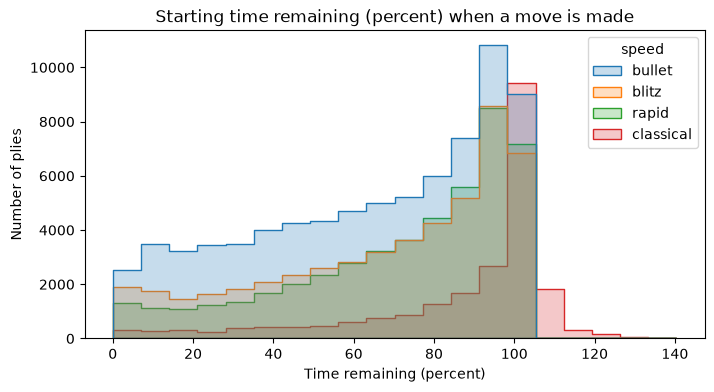

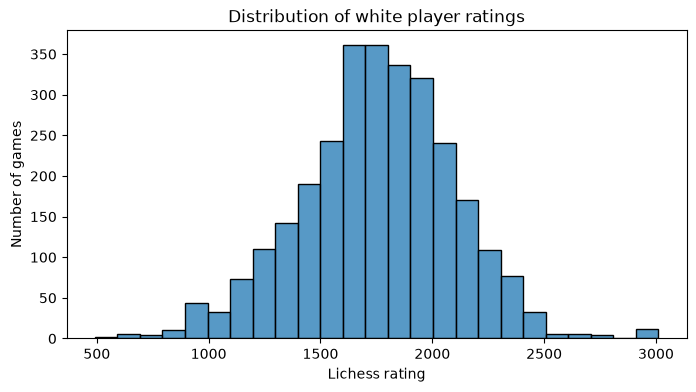

In [ ]:
# Univariate plots
plt.figure(figsize=(8, 4))
sns.histplot(
    data=moves_df, x="pct_time_remaining", hue="speed", bins=20, element="step"
)
plt.title("Starting time remaining (percent) when a move is made")
plt.xlabel("Time remaining (percent)")
plt.ylabel("Number of plies")
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(data=games_out, x="white_rating", bins=25)
plt.title("Distribution of white player ratings")
plt.xlabel("Lichess rating")
plt.ylabel("Number of games")
plt.show()

### 5.3 Relationships Between Variables

**Plot 1** directly represents our research question. It initially seems to supports the idea that more time = fewer blunders because the 90%+ bin is
  far below the others. However, below 90%, the lines are flat or even slope the wrong way.

  **Plot 2** explains this occurrence. Blunder rate depends strongly on game phase. In the first 10 plies, blunders are very rare (under 2%) because players are playing memorized opening moves. The opening is also where everyone has a full clock. Blunders peak in the middlegame (plies 30 to 50, about 10%), where positions get complicated, then drop in the endgame.

  **Plot 3** removes the first 20 plies. Removing the opening moves is a way to control for that confounder.
  The only clear effect left is in bullet where with under 10% of the clock left, blunder rate rises to 10.5%. Classical is noisy because it
  has way fewer low-time plies.

  **Plot 4** checks rating as a confounder. Blunder rate drops steadily with player rating from about 10% near 1000 to under
  3% near 3000, so rating must be included in the model.


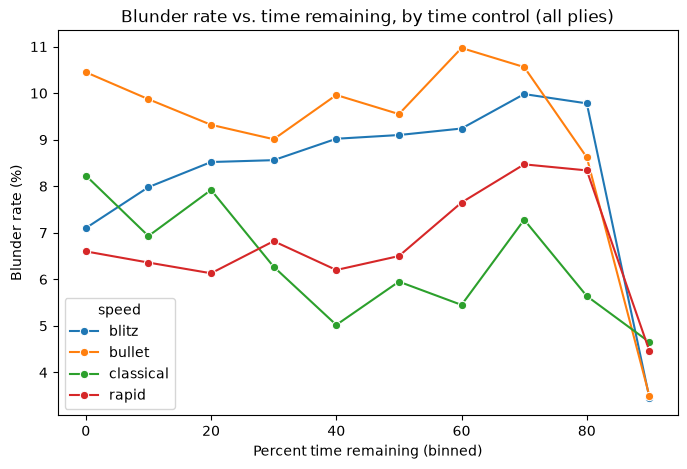

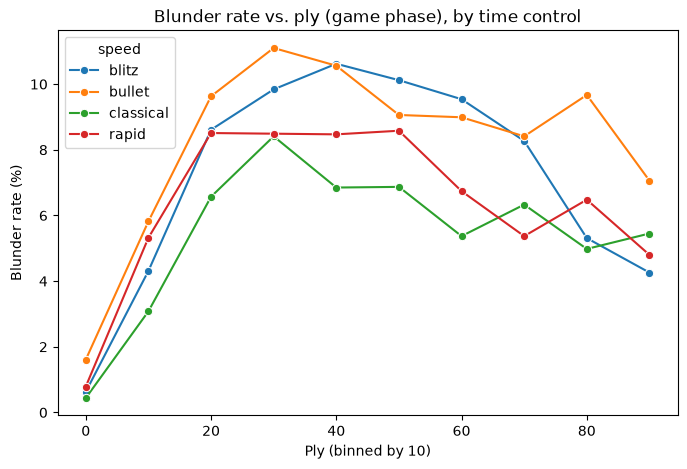

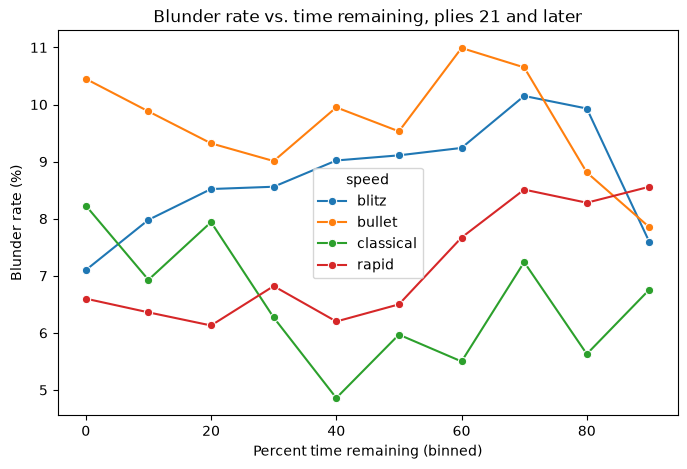

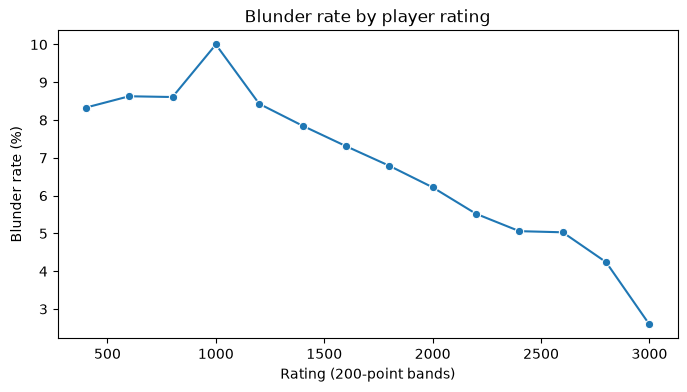

In [ ]:
# Bivariate plots

rate_by_bin = duckdb.sql("""
    SELECT speed,
           LEAST(FLOOR(pct_time_remaining / 10) * 10, 90) AS time_bin,
           COUNT(*) AS n_plies,
           ROUND(100 * AVG(is_blunder), 2) AS blunder_pct
    FROM moves_df
    GROUP BY speed, time_bin
    ORDER BY speed, time_bin
""").df()
plt.figure(figsize=(8, 5))
sns.lineplot(data=rate_by_bin, x="time_bin", y="blunder_pct", hue="speed", marker="o")
plt.title("Blunder rate vs. time remaining, by time control (all plies)")
plt.xlabel("Percent time remaining (binned)")
plt.ylabel("Blunder rate (%)")
plt.show()

rate_by_ply = duckdb.sql("""
    SELECT speed,
           FLOOR(ply / 10) * 10 AS ply_bin,
           COUNT(*) AS n_plies,
           ROUND(100 * AVG(is_blunder), 2) AS blunder_pct
    FROM moves_df
    WHERE ply < 100
    GROUP BY speed, ply_bin
    ORDER BY speed, ply_bin
""").df()
plt.figure(figsize=(8, 5))
sns.lineplot(data=rate_by_ply, x="ply_bin", y="blunder_pct", hue="speed", marker="o")
plt.title("Blunder rate vs. ply (game phase), by time control")
plt.xlabel("Ply (binned by 10)")
plt.ylabel("Blunder rate (%)")
plt.show()

rate_by_phase = duckdb.sql("""
    SELECT phase,
           LEAST(FLOOR(pct_time_remaining / 10) * 10, 90) AS time_bin,
           COUNT(*) AS n_plies,
           ROUND(100 * AVG(is_blunder), 2) AS blunder_pct
    FROM moves_df
    GROUP BY phase, time_bin
    HAVING COUNT(*) >= 100
    ORDER BY phase, time_bin
""").df()
plt.figure(figsize=(8, 5))
sns.lineplot(data=rate_by_phase, x="time_bin", y="blunder_pct", hue="phase",
             hue_order=["opening", "middlegame", "endgame"], marker="o")
plt.title("Blunder rate vs. time remaining, by game phase")
plt.xlabel("Percent time remaining (binned)")
plt.ylabel("Blunder rate (%)")
plt.show()

rate_by_band = duckdb.sql("""
    SELECT FLOOR(rating / 200) * 200 AS rating_band,
           COUNT(*) AS n_plies,
           ROUND(100 * AVG(is_blunder), 2) AS blunder_pct
    FROM moves_df
    GROUP BY rating_band
    ORDER BY rating_band
""").df()
plt.figure(figsize=(8, 4))
sns.lineplot(data=rate_by_band, x="rating_band", y="blunder_pct", marker="o")
plt.title("Blunder rate by player rating")
plt.xlabel("Rating (200-point bands)")
plt.ylabel("Blunder rate (%)")
plt.show()

### 5.4 EDA Takeaways

*What did the EDA reveal? Did it change the research question(s) or data description?*

- **Time control matters.** Bullet plies are blundered about 1.5 times as often as classical plies (8.0% vs. 5.2%).

**Time remaining matters less than expected.** After excluding the opening, the relationship is 
roughly flat, with a modest rise at very low time in bullet only.

**Game phase is a major confounder.** Low time and late game go together, and the opening is almost
  free of blunders. Any model must control for ply, either by excluding the opening or by including ply as a predictor.

**Rating is a strong predictor** of blundering and should be included as a control.

**Percent of time vs. seconds of time.** 10% remaining is 6 seconds in bullet but 2 minutes in classical. Our
  percentage measure makes the times relative across gamemodes, but absolute seconds may be what actually drives
  blunders. We need to decide which to use before modeling.

**Updated research question.** We keep the question but will phrase the analysis as: controlling for game phase and
  rating, does less time remaining raise the probability of a blunder, and does that effect differ by time control? The
  data description does not change.

## 6. Questions for Reviewers (Part 1)

*Specific questions for peer reviewers and the project mentor, specific to the dataset and based on group discussion.*

1. Should we measure time remaining as a percentage of the starting clock or in absolute seconds? We used percentage so bullet and classical are on the same scale. But 10% remaining is about 6 seconds in bullet and about 2 minutes in classical, and the absolute number of seconds may be what actually causes blunders.

2. What is the best way to control for game phase? The opening is nearly blunder-free and is also when every clock is full. We are deciding between dropping the first 20 plies, which loses data, and keeping all plies with ply as a predictor in a logistic regression. What would be a reasonable cut-off.

3. How should we handle classical games, which have very few low-time plies? Classical players almost never drop below 90% of their clock, so our classical estimates at low time are noisy. Should we keep classical in the model or drop it and keep only rapid, bullet, and blitz, where time pressure actually happens?

---
# Part 2: Preregistration of Analyses

*Preregister at least two analyses that will be presented in the final report regardless of the results. Each statement must include (1) a hypothesis and (2) the analysis that will be run to support it. Do not run these analyses first and then "preregister" them. Remember that the final report must include at least one model showing patterns or relationships between variables that addresses the research question.*

## Preregistration Statement 1

**Hypothesis 1:** 

**Analysis:** 

## Preregistration Statement 2

**Hypothesis 2:** 

**Analysis:** 

## Questions for Reviewers (Part 2)

*Specific questions for the project mentor to answer, looking toward the next stage of the project.*

1. 
2. 
3. 